# imports

In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [2]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [3]:
# specific

from sklearn.decomposition import PCA, TruncatedSVD
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

In [4]:
importlib.reload(read_utils)

<module 'utils_worm.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../src/utils_worm/read_utils.py'>

# setup

In [5]:
ll = 'll00'
data_variant = 'gcamp'

In [6]:
# specific

model_variant = 'ns'
organism = 'worm'
manual = False
full = True

In [7]:
file_id = 20
save = True

In [8]:
max_noi = 40
neurons_of_interest = []
bhl_selection = analysis_utils.get_class_labels(organism)

# load

In [9]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filename, traces, behavior, classes, timestamps, aux = analysis_utils.read_data(organism, file_id)
metadata = (filename, model_path, model_variant, data_variant, manual, full)

significant_impr = analysis_utils.get_significant_neurons(filename, model_variant, mode='impr')
significant_impr = dict(sorted(dict(significant_impr).items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

significant_neurons = analysis_utils.get_significant_neurons(filename, model_variant, mode='hgm')
significant_neurons = dict(sorted(dict(significant_neurons).items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

neuron_labels = (list(significant_impr.keys()) + [label for label in significant_neurons.keys() if label not in significant_impr])[:max_noi]
for neuron in neurons_of_interest:
	if neuron not in neuron_labels and neuron in traces.columns:
		neuron_labels.append(neuron)

In [10]:
if organism == 'worm':
	classes_display = classes.copy()
	classes_display['FWD'] = np.logical_or(
		classes_display['FWD'].values,
		classes_display['SLOWING'].values
	).astype(np.intp)
	classes_display = classes_display.drop('SLOWING', axis=1)

	classes_display['UNKNOWN'] = np.logical_or(
		classes_display['UNKNOWN'].values,
		classes_display['TRACKING_FAILURE'].values
	).astype(np.intp)
	classes_display = classes_display.drop('TRACKING_FAILURE', axis=1)

	classes_display = classes_display.reindex(columns=['FWD', 'REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE', 'UNKNOWN'])

if organism == 'fly':
	classes_display = classes.copy()
	classes_display = classes_display.reindex(columns=['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move'])

# manifold

In [11]:
bom_params, hgm_params = analysis_utils.read_models(*metadata)

((_, bom_man, bom_rec, bom_res, bom_pres, bom_resss, bom_bss),
 (_, hgm_man, hgm_rec, hgm_res, hgm_pres, hgm_resss, hgm_bss)) = analysis_utils.read_predictions(*metadata)

bom_manifolds, bom_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)
hgm_manifolds, hgm_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)

In [12]:
(pca_modes, _, _,
 pca_vars_expl) = train_utils.get_manifolds_pca(
	[traces],
	scale=False, n_pc=hgm_man[0].values.shape[1])

if organism != 'mouse':
	(cca_modes, _, _, _, _, _,
	 cca_vars_expl, cca_vars_expl_rs) = train_utils.get_manifolds_cca(
		[traces], [classes[bhl_selection]],
		scale=False, n_cv=min(hgm_man[0].values.shape[1], classes[bhl_selection].values.shape[1]), n_pc=classes[bhl_selection].values.shape[1])
	(plsc_modes, _, _, _, _, _,
	 plsc_vars_expl) = train_utils.get_manifolds_plsc(
		[traces], [classes[bhl_selection]],
		scale=False, n_ls=min(hgm_man[0].values.shape[1], classes[bhl_selection].values.shape[1]))

### by states

In [ ]:
for i, manifold in enumerate([bom_manifolds, hgm_manifolds, pca_modes] + ([cca_modes, plsc_modes] if organism != 'mouse' else [])):
	var_expl = ([bom_manifold_vars_expl, hgm_manifold_vars_expl, pca_vars_expl] + ([cca_vars_expl, plsc_vars_expl] if organism != 'mouse' else []))[i]
	name = ['bom', 'hgm', 'pca', 'cca', 'pls'][i]

	if organism == 'mouse':
		for cb in ['running_speed', 'pupil_area', 'whisking']:
			plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(len(manifold))],
								  [manifold[s] for s in range(len(manifold))],
								  [aux[0][[cb]] for s in range(len(manifold))],
								  var_expl, None,
								  title=f'{name} manifold', plots_per_row=len(manifold), top_space=0.5,
								  save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_{name}_{cb}' if save else None)

	else:
		plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(manifold))],
								  [manifold[s] for s in range(len(manifold))],
								  [classes_display for s in range(len(manifold))],
								  var_expl, None,
								  title=f'{name} manifold', plots_per_row=len(manifold), top_space=3.5,
								  save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_{name}_states' if save else None)

# manifold by gating

In [21]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))
neuron_ids = [traces.columns.get_loc(neuron) for neuron in neuron_labels]

In [25]:
hgm_man_zs = [(hgm_man[s].values - hgm_man[s].values.mean(axis=0)) / np.where((N_std := hgm_man[s].values.std(axis=0)) == 0.0, 1.0, N_std) for s in range(len(hgm_man))]
WMs = [hgm_params[s]['model']['WM'] for s in range(len(hgm_params))]

gating_term = [pd.DataFrame(sigmoid(hgm_man_zs[s] @ WMs[s]), columns=traces.columns) for s in range(len(hgm_man_zs))]

In [ ]:
for i, manifold in enumerate([bom_manifolds, hgm_manifolds, pca_modes] + ([cca_modes, plsc_modes] if organism != 'mouse' else [])):
	var_expl = ([bom_manifold_vars_expl, hgm_manifold_vars_expl, pca_vars_expl] + ([cca_vars_expl, plsc_vars_expl] if organism != 'mouse' else []))[i]
	name = ['bom', 'hgm', 'pca', 'cca', 'pls'][i]

	titles = [f'{label} (R² impr: {(significant_neurons[label][1] - significant_neurons[label][0]).reshape(-1).item():.2f}{(', sig' if label in significant_impr else '')})' for label in neuron_labels]

	plot_utils.plot_manifolds_gradient(titles,
									   [manifold[0]] * len(neuron_ids),
									   [gating_term[0].iloc[:, n_id] for n_id in neuron_ids],
									   var_expl * len(neuron_ids), None,
									   title=f'{str(file_id)}: {filename} gcamp {name} manifolds by gating of the different neurons',
									   plots_per_row=3, top_space=1,
									   save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_{name}_gating' if save else None)

In [26]:
modes = hgm_pres[0].shape[1]# + 1
columns = [f'Mode {i+1}' for i in range(modes)]

In [27]:
svd_gating = [PCA(n_components=modes) for s in range(len(gating_term))]
# svd_gating = [TruncatedSVD(n_components=modes) for s in range(len(gating_term))]
for s, svd_gating_s in enumerate(svd_gating):
	svd_gating_s.fit(gating_term[s].values)

0.99998903


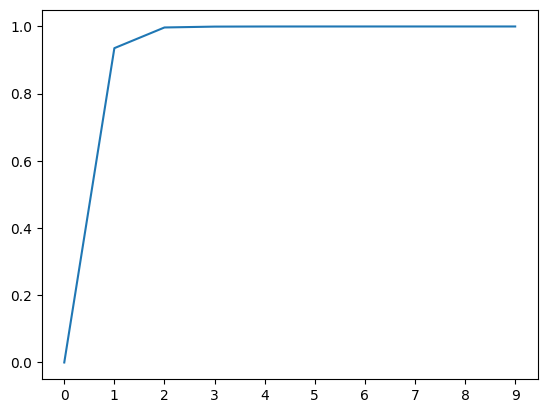

In [33]:
n_modes = 10

plt.xticks(range(modes+1)[:n_modes])
plt.plot([sum(svd_gating[0].explained_variance_ratio_[:k]) for k in range(modes+1)[:n_modes]])
print(sum(svd_gating[0].explained_variance_ratio_[:modes+1][:n_modes]))
os.makedirs(f'../../out/plots/manifolds/{filename}', exist_ok=True)

plt.savefig(f'../../out/plots/manifolds/{filename}/gating_space_dim_ns')
np.save(f'../../out/plots/manifolds/{filename}/gating_space_dim_ns', svd_gating[0].explained_variance_ratio_)

In [30]:
gating_term_modes = [pd.DataFrame(svd_gating[s].transform(gating_term[s].values), columns=columns) for s in range(len(gating_term))]

In [31]:
bom_pres_modes = [pd.DataFrame(svd_gating[s].transform(bom_pres[s].values), columns=columns) for s in range(len(bom_pres))]
hgm_pres_modes = [pd.DataFrame(svd_gating[s].transform(hgm_pres[s].values), columns=columns) for s in range(len(hgm_pres))]

bom_res_modes = [pd.DataFrame(svd_gating[s].transform(bom_res[s].values), columns=columns) for s in range(len(bom_res))]
hgm_res_modes = [pd.DataFrame(svd_gating[s].transform(hgm_res[s].values), columns=columns) for s in range(len(hgm_res))]

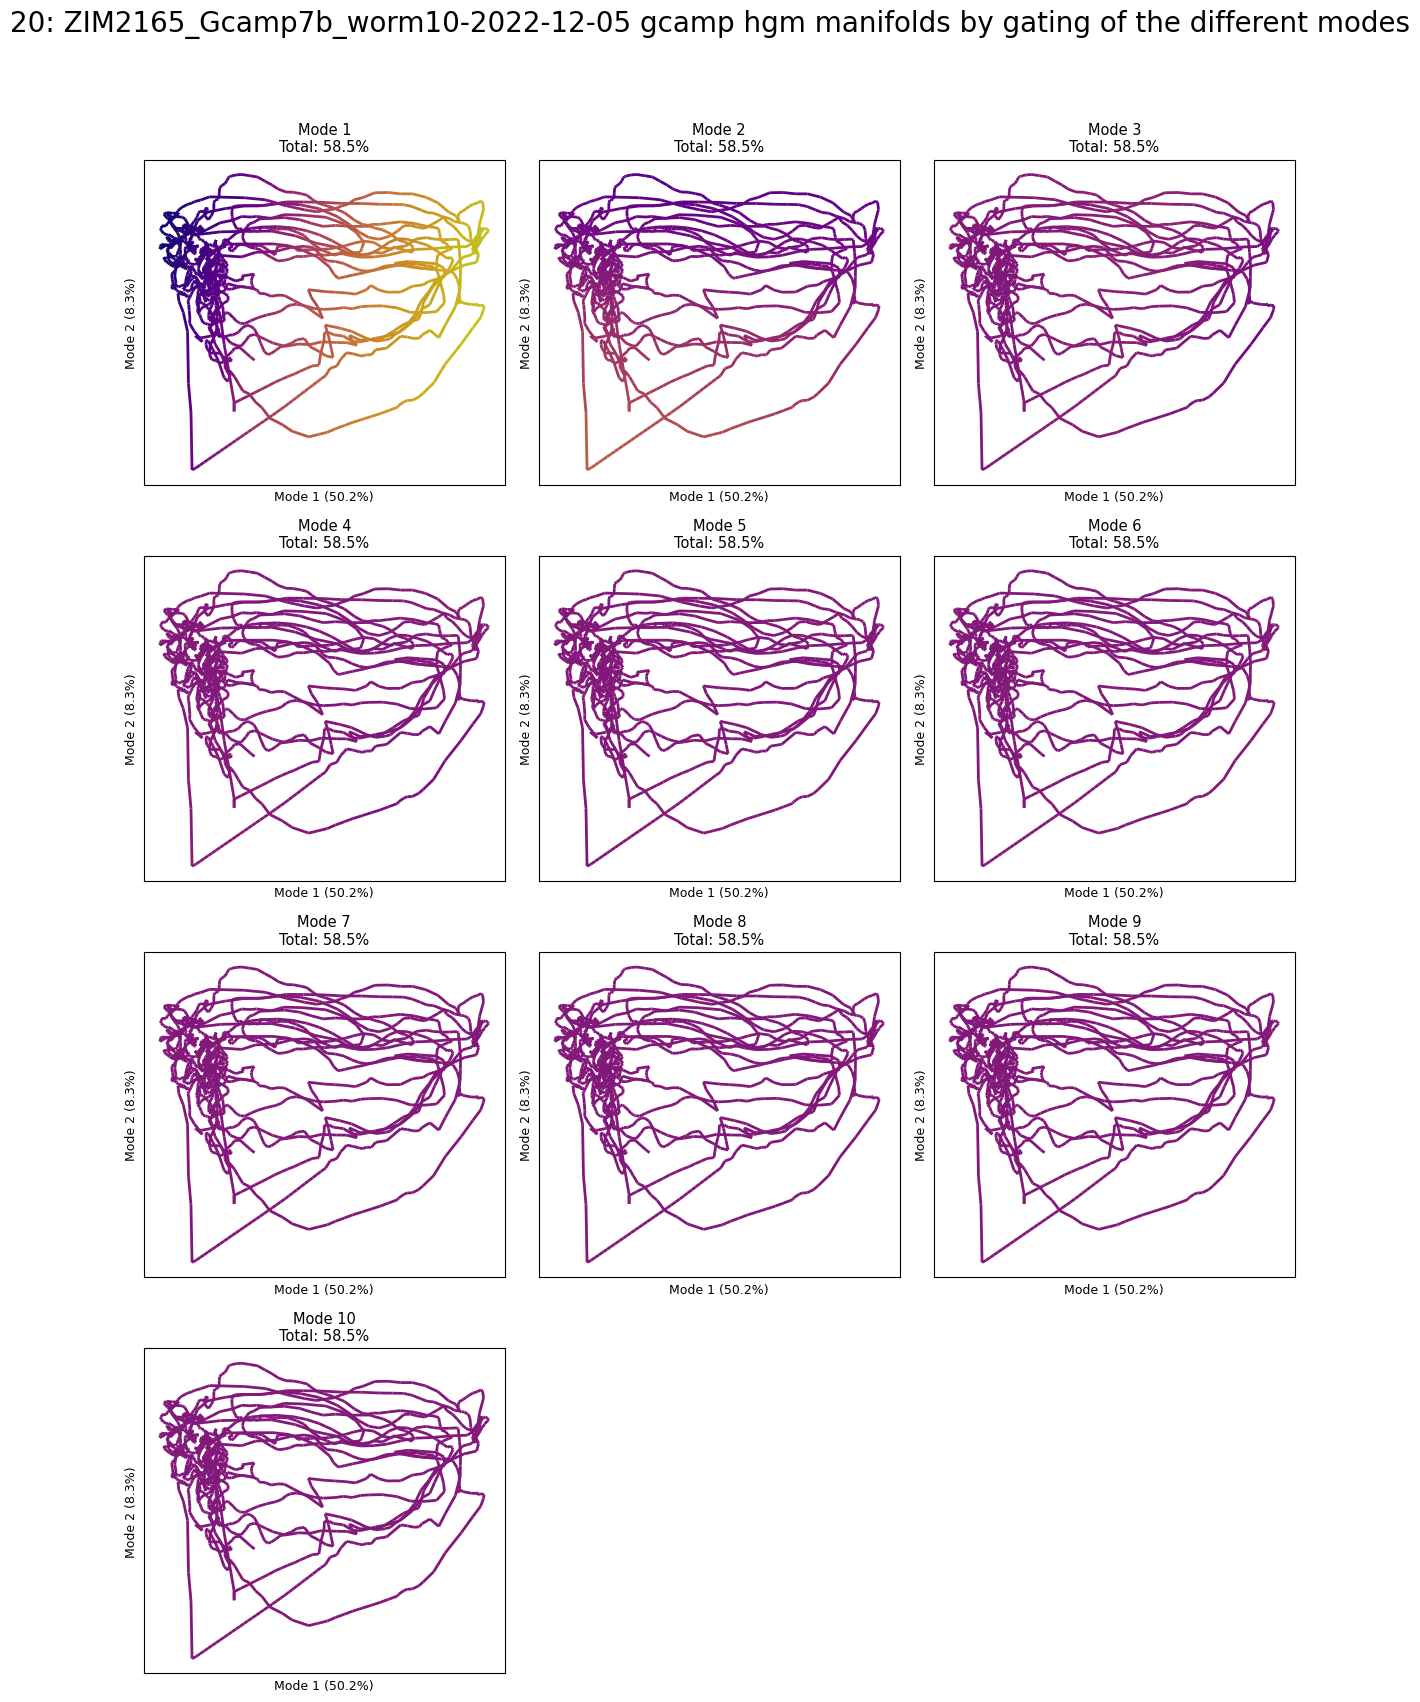

58.5%


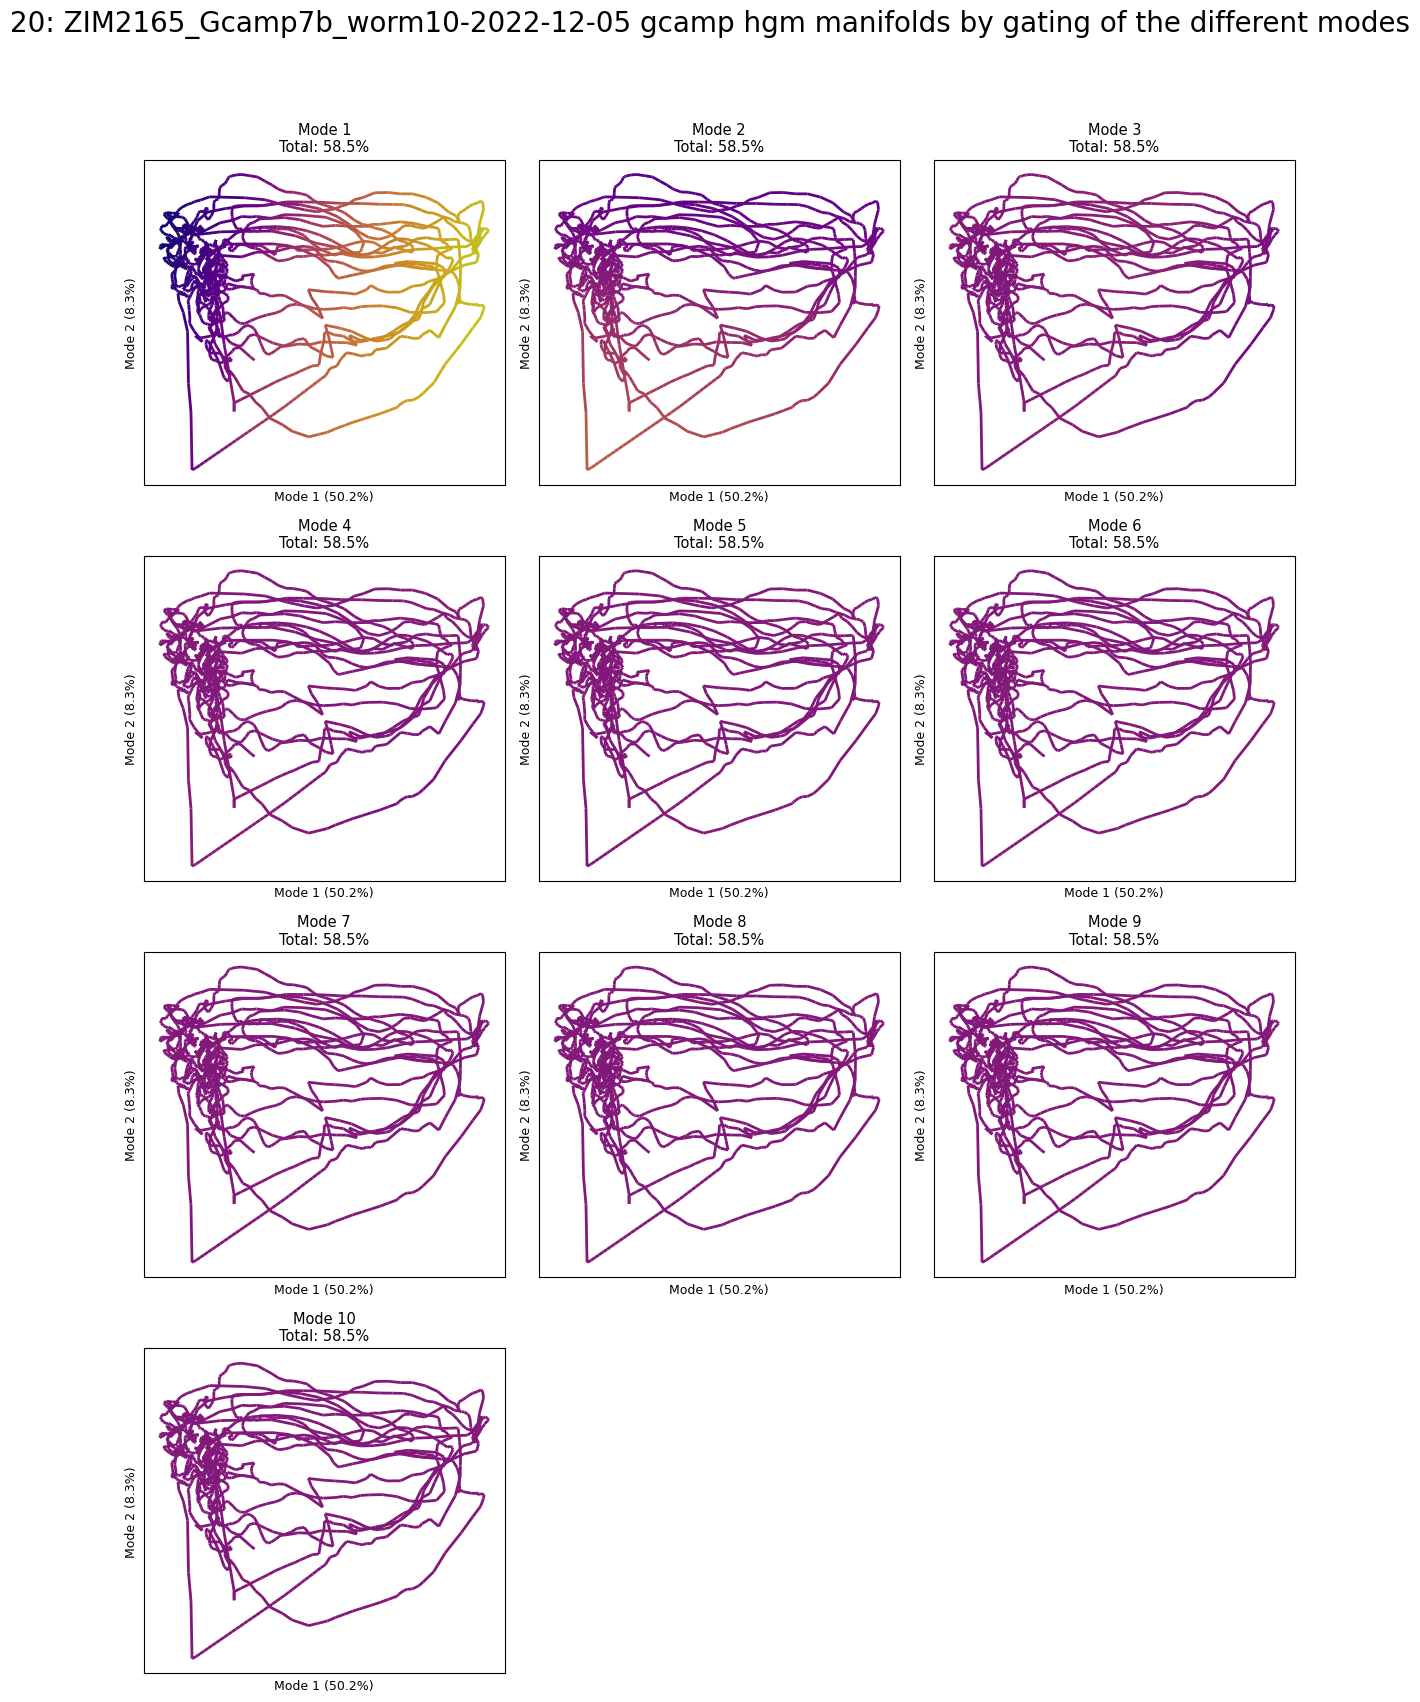

58.5%


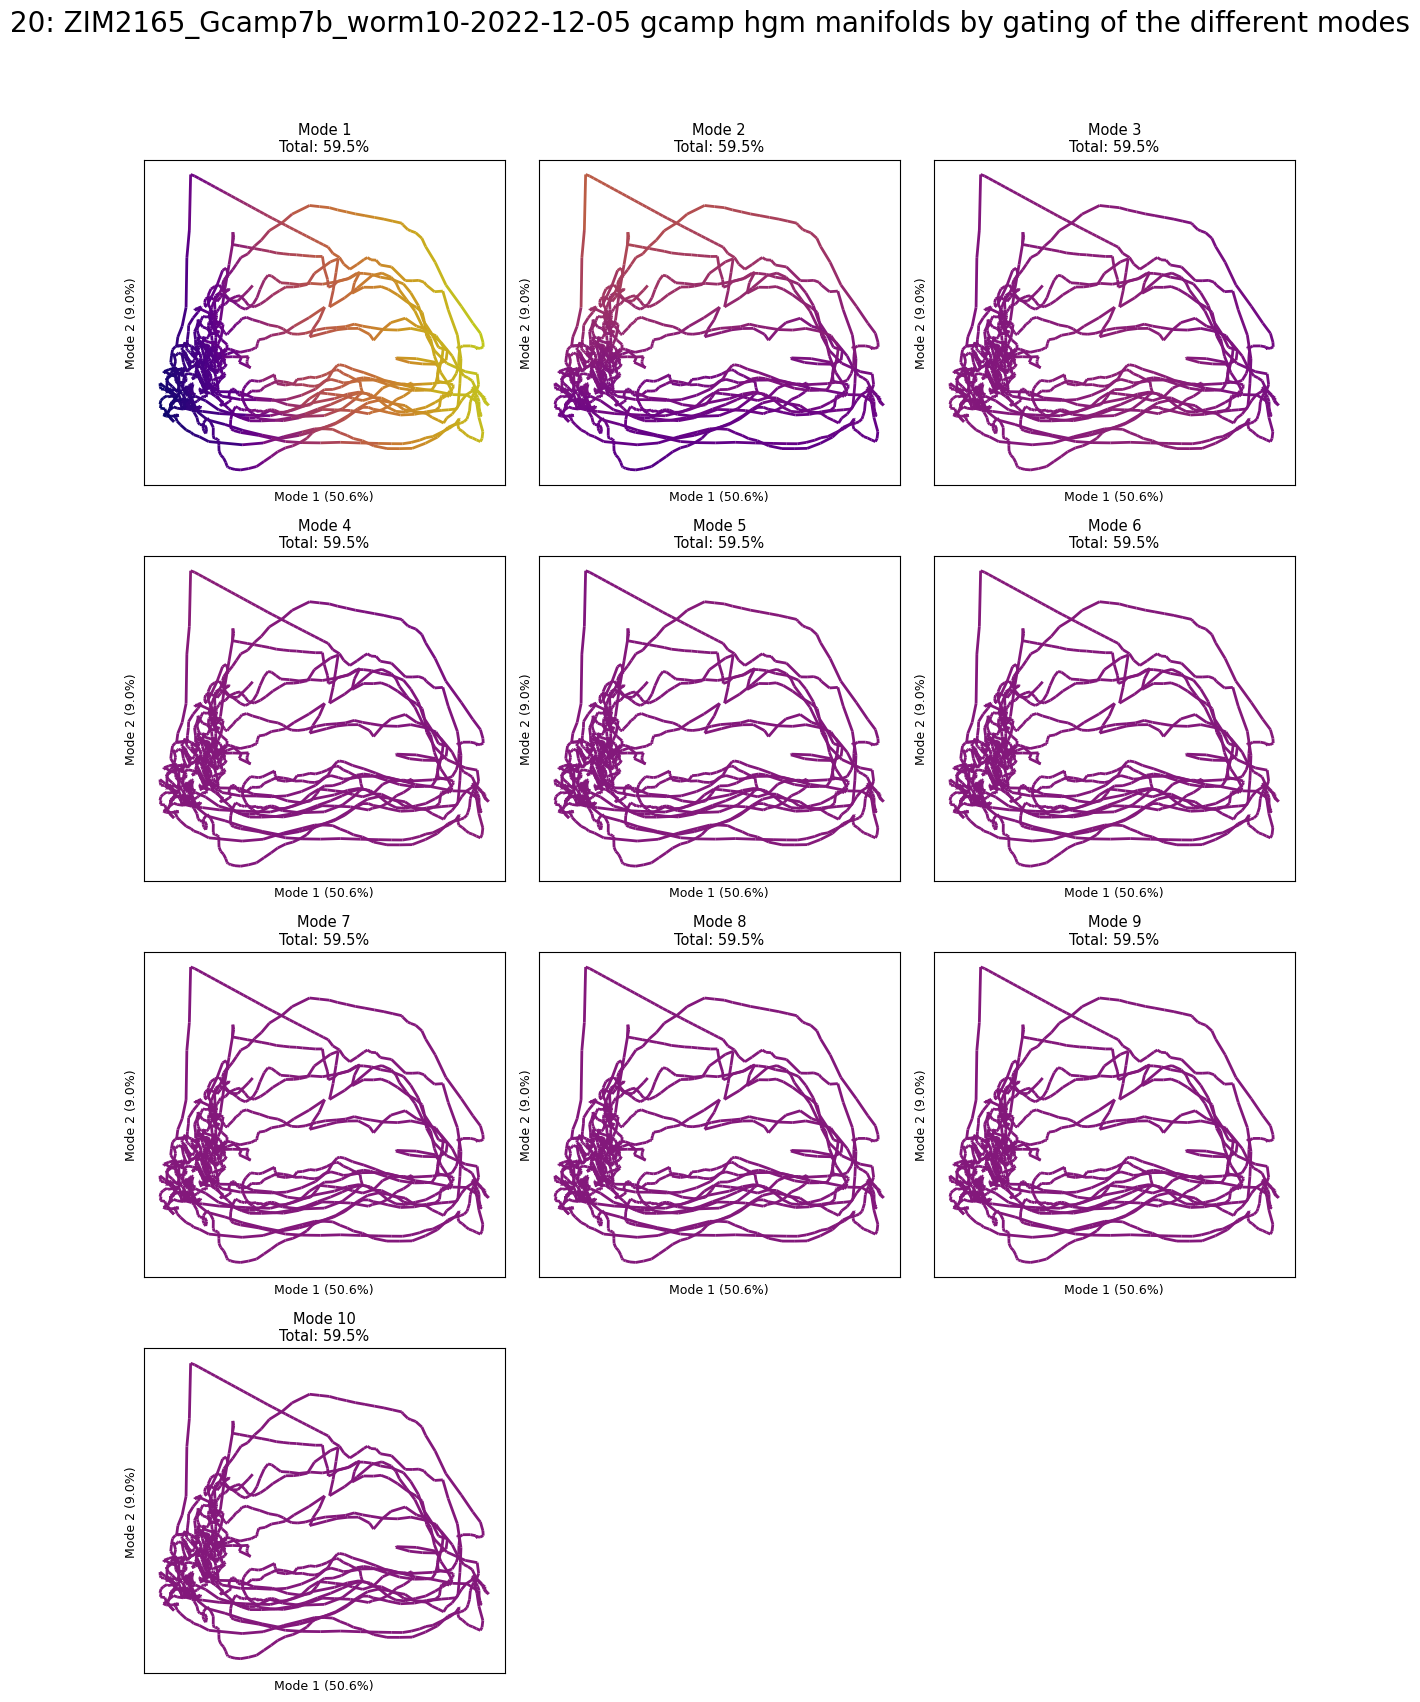

59.5%


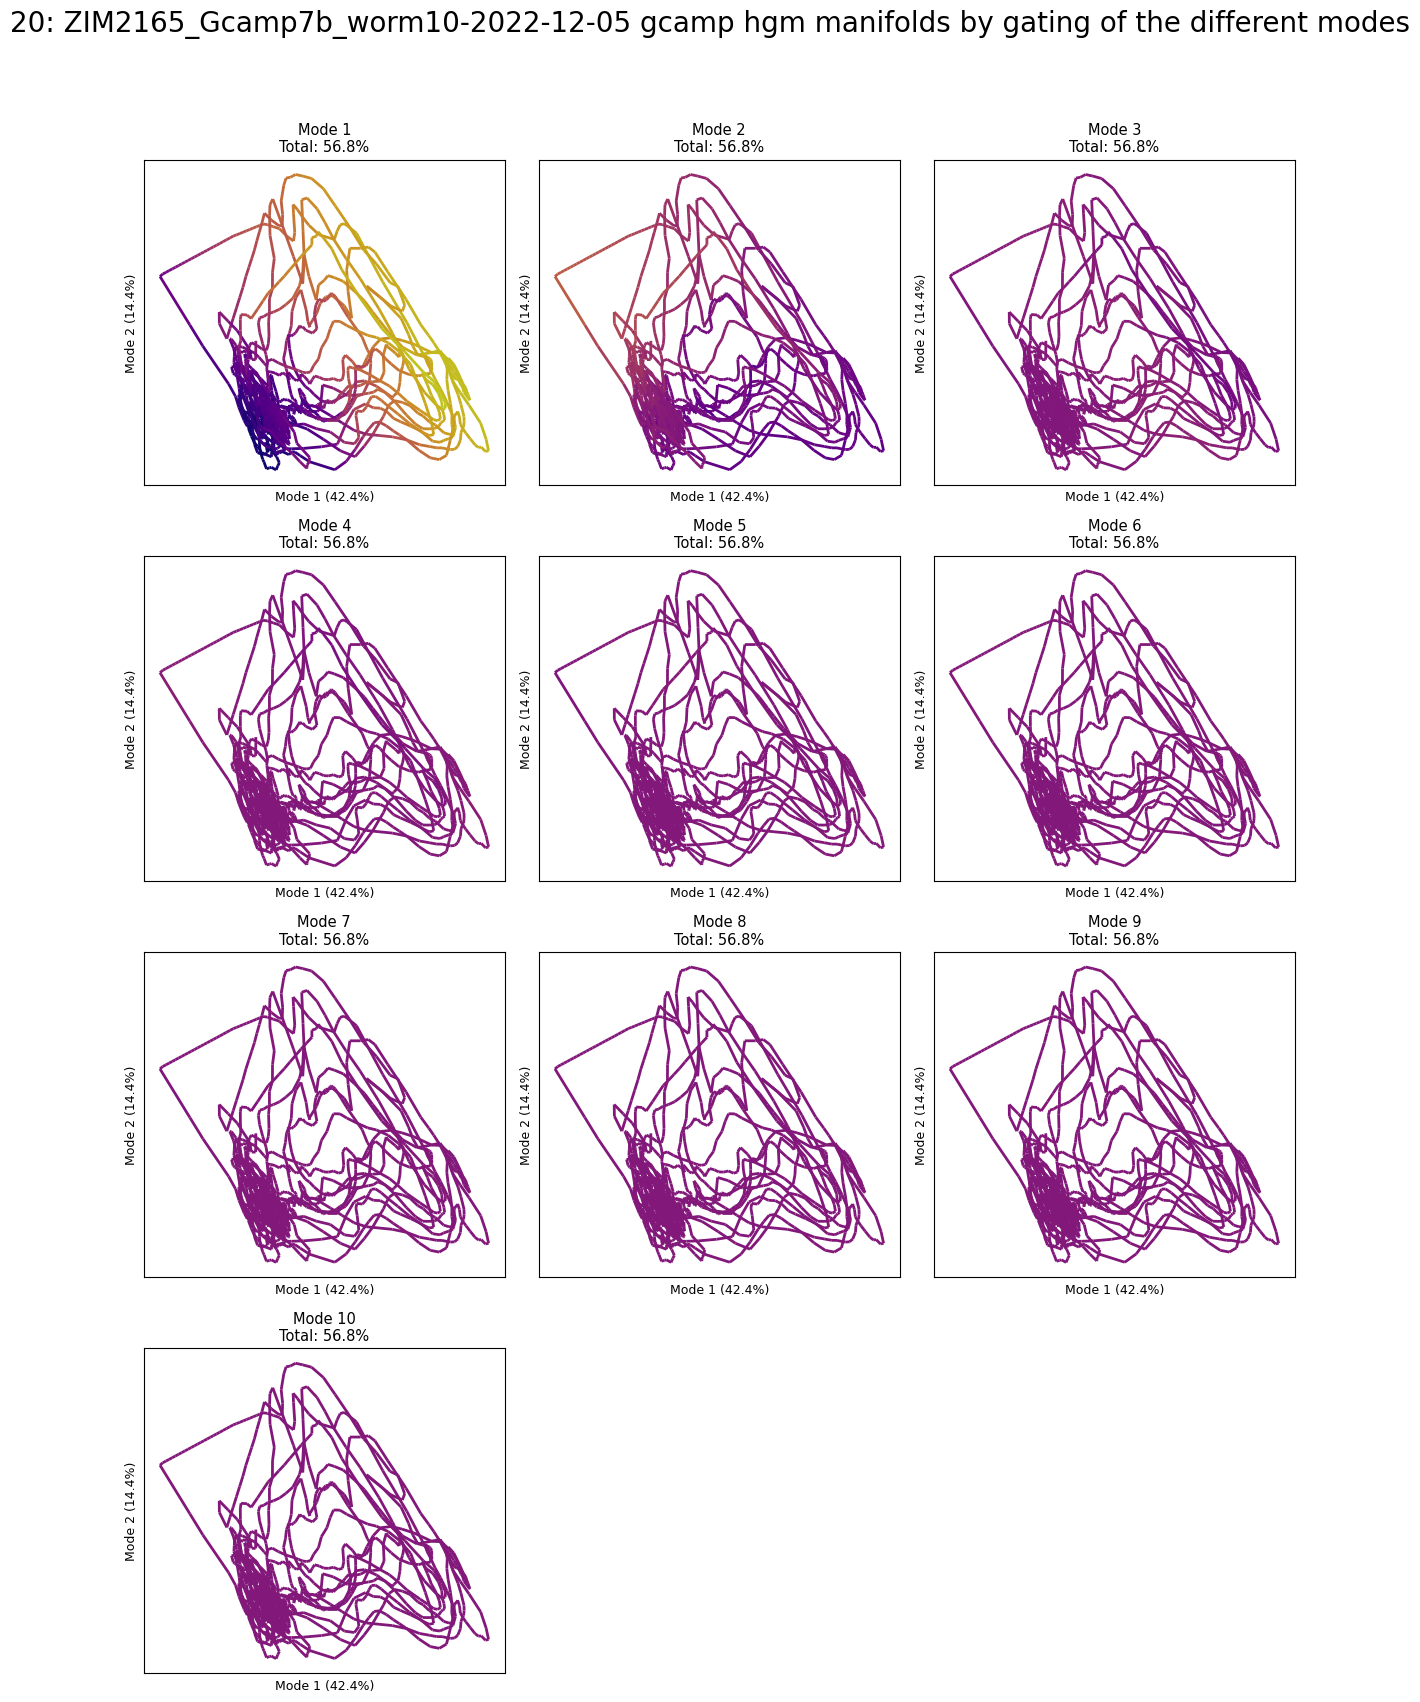

56.8%


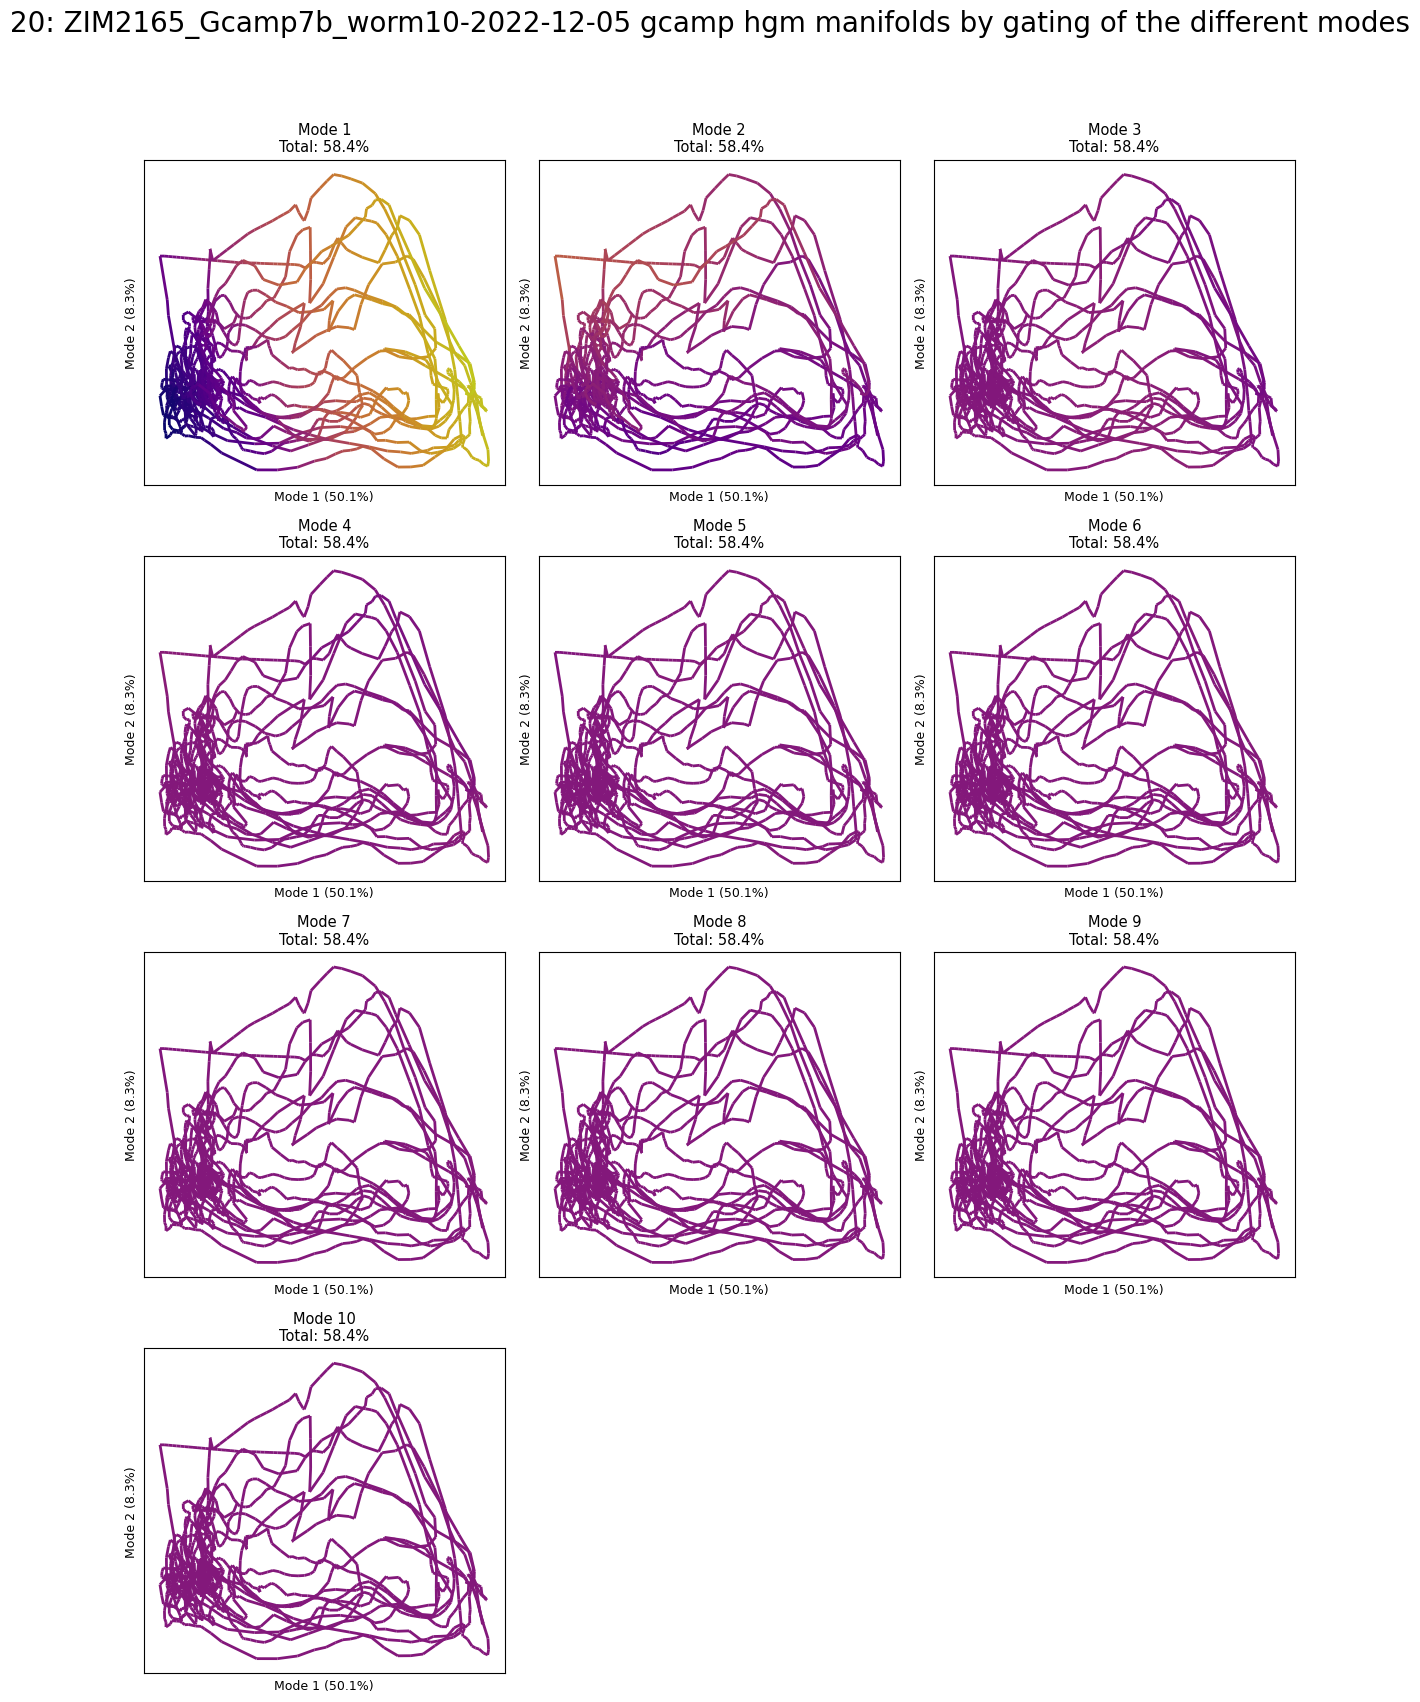

58.4%


In [34]:
for i, manifold in enumerate([bom_manifolds, hgm_manifolds, pca_modes] + ([cca_modes, plsc_modes] if organism != 'mouse' else [])):
	var_expl = ([bom_manifold_vars_expl, hgm_manifold_vars_expl, pca_vars_expl] + ([cca_vars_expl, plsc_vars_expl] if organism != 'mouse' else []))[i]
	name = ['bom', 'hgm', 'pca', 'cca', 'pls'][i]

	plot_utils.plot_manifolds_gradient([f'Mode {ss+1}' for ss in range(modes)[:n_modes]],
								   [manifold[0]] * n_modes,
								   [gating_term_modes[0][[f'Mode {ss+1}']] for ss in range(modes)[:n_modes]],
								   var_expl * n_modes, None,
								   title=f'{str(file_id)}: {filename} gcamp hgm manifolds by gating of the different modes',
								   plots_per_row=3, top_space=1,
								   save_path=None)
									# save_path=f'../../out/plots/manifolds/{filename}/{model_variant}_{name}_gating_modes' if save else None